# Linear Regression from Scratch

Batch gradient descent on the bundled California housing dataset, compared with sklearn. Open this notebook in the repository root and run all cells from a fresh kernel.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from experiment import ROOT, run_experiment, save_plots
from model import LinearRegressionScratch


## Data preparation

Drop rows with missing values and omit ocean_proximity for this numerical baseline. Use an 80/20 split with seed 42. StandardScaler is fitted only on training data. The model learns both weights and an intercept.

In [2]:
df = pd.read_csv(ROOT / "data" / "california_housing.csv")
print("Original rows:", len(df))
print(df.isna().sum())
df.head()


Original rows: 20640
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,NEAR BAY,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,NEAR BAY,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,NEAR BAY,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,NEAR BAY,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,NEAR BAY,342200


## Gradient descent

Prediction: Xw + b. Training cost: mean((prediction - y)^2) / 2. The weight gradient is X.T @ error / n; the intercept gradient is mean(error). Each experiment starts from zero and performs exactly 500, 2000, or 5000 updates at learning rate 0.01.

In [3]:
results, (models, X_test, y_test) = run_experiment()
pd.DataFrame(results["models"]).T


,mse,rmse,r2
500,5.647828e+09,75152.035103,0.587002
2000,5.007516e+09,70763.802236,0.633825
5000,4.922703e+09,70161.980264,0.640026
sklearn,4.921881e+09,70156.120457,0.640087


## Correct evaluation

R² = 1 - sum((y - prediction)^2) / sum((y - mean(y))^2). The implementation uses sklearn.metrics.r2_score. Using only the variance of residuals would incorrectly ignore a constant prediction bias. RMSE is in the same units as the target house values.

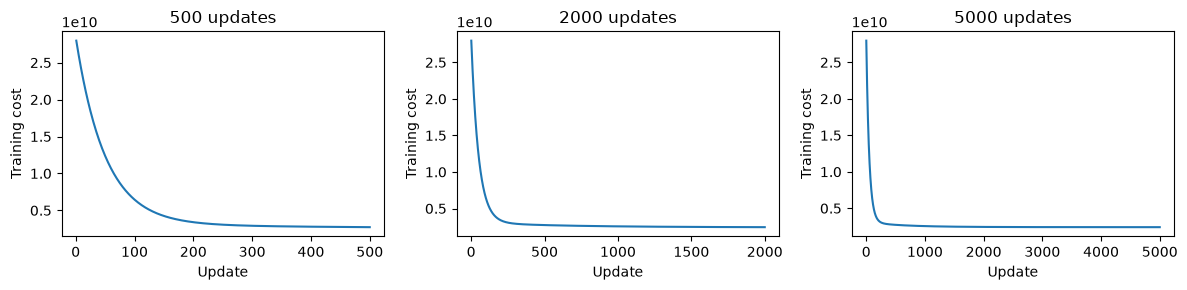

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for label, ax in zip(["500", "2000", "5000"], axes):
    ax.plot(np.arange(1, len(models[label].cost_history_) + 1), models[label].cost_history_)
    ax.set(title=f"{label} updates", xlabel="Update", ylabel="Training cost")
plt.tight_layout()
plt.show()


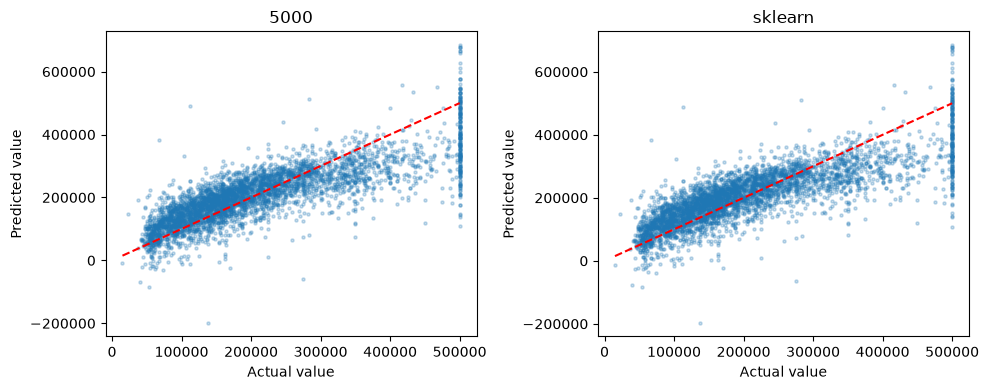

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, ax in zip(["5000", "sklearn"], axes):
    pred = models[label].predict(X_test)
    ax.scatter(y_test, pred, s=5, alpha=0.25)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    ax.set(title=label, xlabel="Actual value", ylabel="Predicted value")
plt.tight_layout()
plt.show()


## Recreate figures

The next cell updates the versioned images from the same experiment results.

In [6]:
save_plots(models, X_test, y_test)


## Limitations

This is an educational numerical baseline: a linear model, random split, dropped missing rows, and no categorical or spatial modeling. Iteration counts illustrate convergence; do not select future hyperparameters on the test set. These corrected results supersede the original metrics and figures.